## Regression Case Study

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

from sklearn.model_selection import train_test_split
from sklearn.linear_model import LinearRegression, Lasso
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import r2_score, mean_absolute_error, mean_squared_error

In [2]:
df = pd.read_csv("car_age_price.csv")
df.head()

,Year,Price
0,2018,465000
1,2019,755000
2,2019,700000
3,2018,465000
4,2018,465000


In [3]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 112 entries, 0 to 111
Data columns (total 2 columns):
 #   Column  Non-Null Count  Dtype
---  ------  --------------  -----
 0   Year    112 non-null    int64
 1   Price   112 non-null    int64
dtypes: int64(2)
memory usage: 1.9 KB


In [4]:
df.describe()

,Year,Price
count,112.000000,112.000000
mean,2016.669643,483866.044643
std,1.629616,91217.450533
min,2013.000000,300000.000000
25%,2015.000000,423750.000000
50%,2017.000000,500000.000000
75%,2017.000000,550000.000000
max,2020.000000,755000.000000


In [5]:
df.isnull().sum()

Year     0
Price    0
dtype: int64

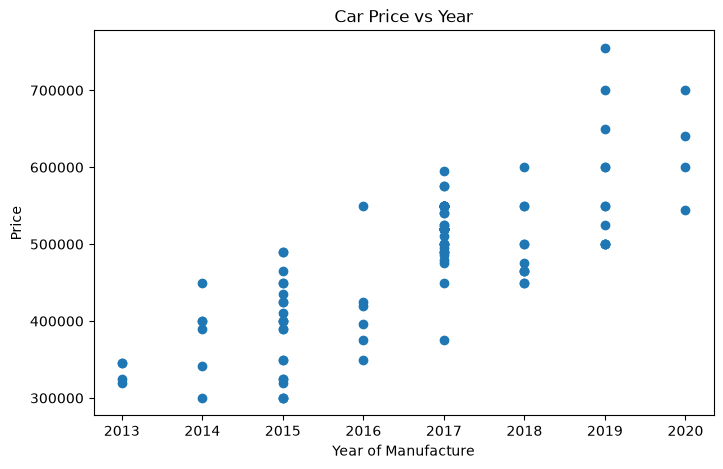

In [6]:
plt.figure(figsize=(8, 5))
plt.scatter(df["Year"], df["Price"])
plt.xlabel("Year of Manufacture")
plt.ylabel("Price")
plt.title("Car Price vs Year")
plt.show()

In [7]:
X = df[["Year"]]
y = df["Price"]

print("Input feature:")
display(X.head())

print("Target variable:")
display(y.head())

Input feature:


,Year
0,2018
1,2019
2,2019
3,2018
4,2018


Target variable:


0    465000
1    755000
2    700000
3    465000
4    465000
Name: Price, dtype: int64

In [8]:
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42
)

print("Training data:", X_train.shape)
print("Testing data:", X_test.shape)

Training data: (89, 1)
Testing data: (23, 1)


### Linear Regression Model

In [9]:
linear_model = LinearRegression()
linear_model.fit(X_train, y_train)
linear_predictions = linear_model.predict(X_test)
print("Linear Regression Coefficient:", linear_model.coef_[0])
print("Linear Regression Intercept:", linear_model.intercept_)

Linear Regression Coefficient: 47608.5678080766
Linear Regression Intercept: -95520922.49198584


In [10]:
linear_r2 = r2_score(y_test, linear_predictions)
linear_mae = mean_absolute_error(y_test, linear_predictions)
linear_rmse = np.sqrt(mean_squared_error(y_test, linear_predictions))
print("Linear Regression Results")
print("R2 Score:", linear_r2)
print("Mean Absolute Error:", linear_mae)
print("Root Mean Squared Error:", linear_rmse)

Linear Regression Results
R2 Score: 0.36759313425902185
Mean Absolute Error: 53534.77957001264
Root Mean Squared Error: 65779.22359552195


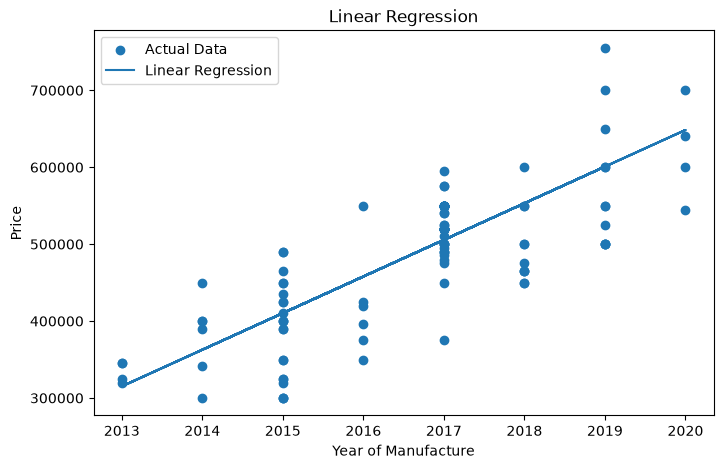

In [11]:
plt.figure(figsize=(8, 5))
plt.scatter(X, y, label="Actual Data")
plt.plot(X, linear_model.predict(X), label="Linear Regression")
plt.xlabel("Year of Manufacture")
plt.ylabel("Price")
plt.title("Linear Regression")
plt.legend()
plt.show()

### Lasso Regression Model

In [12]:
lasso_scaler = StandardScaler()
X_train_scaled = lasso_scaler.fit_transform(X_train)
X_test_scaled = lasso_scaler.transform(X_test)

In [13]:
lasso_model = Lasso(alpha=1.0)
lasso_model.fit(X_train_scaled, y_train)
lasso_predictions = lasso_model.predict(X_test_scaled)
print("Lasso Regression model trained successfully.")

Lasso Regression model trained successfully.


In [14]:
lasso_r2 = r2_score(y_test, lasso_predictions)
lasso_mae = mean_absolute_error(y_test, lasso_predictions)
lasso_rmse = np.sqrt(mean_squared_error(y_test, lasso_predictions))

print("Lasso Regression Results")
print("R2 Score:", lasso_r2)
print("Mean Absolute Error:", lasso_mae)
print("Root Mean Squared Error:", lasso_rmse)

Lasso Regression Results
R2 Score: 0.3676037165070517
Mean Absolute Error: 53534.07982431269
Root Mean Squared Error: 65778.67324177896


C:\Users\MidhunWork\AppData\Roaming\Python\Python313\site-packages\sklearn\utils\validation.py:2823: UserWarning: X has feature names, but Lasso was fitted without feature names
  warnings.warn(


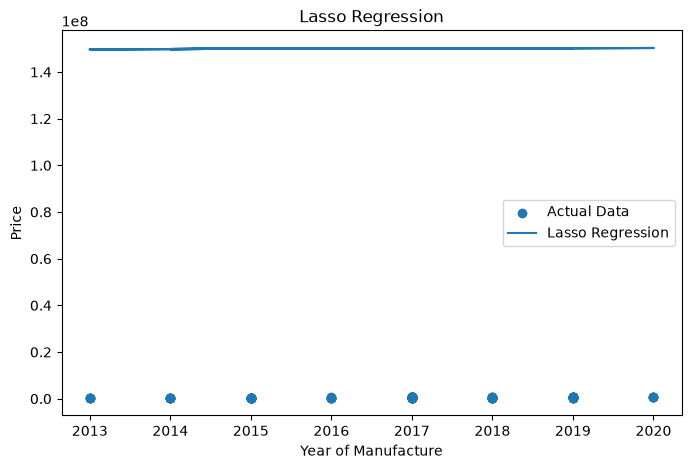

In [15]:
plt.figure(figsize=(8, 5))
plt.scatter(X, y, label="Actual Data")
plt.plot(X, lasso_model.predict(X), label="Lasso Regression")
plt.xlabel("Year of Manufacture")
plt.ylabel("Price")
plt.title("Lasso Regression")
plt.legend()
plt.show()

### Compare Both Models

In [16]:
comparison = pd.DataFrame({
    "Model": ["Linear Regression", "Lasso Regression"],
    "R2 Score": [linear_r2, lasso_r2],
    "MAE": [linear_mae, lasso_mae],
    "RMSE": [linear_rmse, lasso_rmse]
})

comparison

,Model,R2 Score,MAE,RMSE
0,Linear Regression,0.367593,53534.779570,65779.223596
1,Lasso Regression,0.367604,53534.079824,65778.673242


In [17]:
if lasso_r2 > linear_r2:
    print("Lasso Regression performs better based on the R2 Score.")
elif linear_r2 > lasso_r2:
    print("Linear Regression performs better based on the R2 Score.")
else:
    print("Both models have the same R2 Score.")

Lasso Regression performs better based on the R2 Score.


### Predict the Price of a 2022 Model

In [18]:
final_linear_model = LinearRegression()
final_linear_model.fit(X, y)
final_lasso_scaler = StandardScaler()
X_scaled = final_lasso_scaler.fit_transform(X)

In [19]:
final_lasso_model = Lasso(alpha=1.0)
final_lasso_model.fit(X_scaled, y)

,"alpha alpha: float, default=1.0Constant that multiplies the L1 term, controlling regularizationstrength. `alpha` must be a non-negative float i.e. in `[0, inf)`.When `alpha = 0`, the objective is equivalent to ordinary leastsquares, solved by the :class:`LinearRegression` object. For numericalreasons, using `alpha = 0` with the `Lasso` object is not advised.Instead, you should use the :class:`LinearRegression` object.",1.0
,"fit_intercept fit_intercept: bool, default=TrueWhether to calculate the intercept for this model. If setto False, no intercept will be used in calculations(i.e. data is expected to be centered).",True
,"precompute precompute: bool or array-like of shape (n_features, n_features), default=FalseWhether to use a precomputed Gram matrix to speed upcalculations. The Gram matrix can also be passed as argument.For sparse input this option is always ``False`` to preserve sparsity.",False
,"copy_X copy_X: bool, default=TrueIf ``True``, X will be copied; else, it may be overwritten.",True
,"max_iter max_iter: int, default=1000The maximum number of iterations.",1000
,"tol tol: float, default=1e-4The tolerance for the optimization: if the updates are smaller or equal to``tol``, the optimization code checks the dual gap for optimality and continuesuntil it is smaller or equal to ``tol``, see Notes below.",0.0001
,"warm_start warm_start: bool, default=FalseWhen set to ``True``, reuse the solution of the previous call to fit asinitialization, otherwise, just erase the previous solution.See :term:`the Glossary <warm_start>`.",False
,"positive positive: bool, default=FalseWhen set to ``True``, forces the coefficients to be positive.",False
,"random_state random_state: int, RandomState instance, default=NoneThe seed of the pseudo random number generator that selects a randomfeature to update. Used when ``selection`` == 'random'.Pass an int for reproducible output across multiple function calls.See :term:`Glossary <random_state>`.",None
,"selection selection: {'cyclic', 'random'}, default='cyclic'If set to 'random', a random coefficient is updated every iterationrather than looping over features sequentially by default. This(setting to 'random') often leads to significantly faster convergenceespecially when tol is higher than 1e-4.",'cyclic'
Name,Type,Value


In [20]:
new_car = pd.DataFrame({"Year": [2022]})
new_car_scaled = final_lasso_scaler.transform(new_car)

In [21]:
linear_price = final_linear_model.predict(new_car)[0]
lasso_price = final_lasso_model.predict(new_car_scaled)[0]

print("Predicted price for 2022 model using Linear Regression: ₹", round(linear_price, 2))
print("Predicted price for 2022 model using Lasso Regression: ₹", round(lasso_price, 2))

Predicted price for 2022 model using Linear Regression: ₹ 715488.08
Predicted price for 2022 model using Lasso Regression: ₹ 715484.79


### Conclusion

The two models are compared using their R2 Score, MAE and RMSE. The model with the higher R2 Score and lower error values performs better on the test data.

The predicted price for a 2022 Hyundai Grand i10 is an estimate based on the relationship learned from the available dataset. Actual second-hand car prices may differ depending on condition, mileage, location and other factors.